In [24]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [25]:
def load_power_spectrum(file):

    table = pd.read_csv(file,
    sep=r"\s+",
    comment="#",
    names=["k (h/Mpc)", "P_k (Mpc/h)^3", "P_linear_k (Mpc/h)^3"])

    k = table["k (h/Mpc)"]
    Pk = table["P_k (Mpc/h)^3"]

    return k, Pk

# Load power spectra

In [26]:
import os

# The Abacus matter P(k) is computed by a batch job, not inline here: painting the full
# particle subsample (halo-bound + field particles) onto a mesh needs several GB, which
# doesn't fit in a shared login-node session. Run it with:
#   sbatch /home/biel/Hi-COLA/power_spectrum_abacus.sh
# (edit the "user parameters" block at the top of that script first if the box/redshift
# changed). It writes Abacus_<model>_z<redshift>.txt in Bart's column format, so it loads
# with the existing load_power_spectrum() helper.

abacus_model = "LCDM"
abacus_redshift = 0.500  # matches REDSHIFT in power_spectrum_abacus.sh
abacus_redshift_label = f"{abacus_redshift:.3f}"

abacus_pk_file = f"/home/biel/Hi-COLA/Comparison/Abacus1/Abacus_{abacus_model}_z{abacus_redshift_label}.txt"

if not os.path.exists(abacus_pk_file):
    raise FileNotFoundError(
        f"Missing {abacus_pk_file}. Run sbatch /home/biel/Hi-COLA/power_spectrum_abacus.sh first."
    )

k_LCDM_Abacus, Pk_LCDM_Abacus = load_power_spectrum(abacus_pk_file)

# Our own COLA runs to compare against the Abacus box, loaded the same way as the
# LCDM_Bart/nDGP_Bart comparison sims above.
k_LCDM_Abacus_Me, Pk_LCDM_Abacus_Me = load_power_spectrum(
    f'/scratch/biel/LCDM_Abacus/snapshot_LCDM_Abacus_z{abacus_redshift_label}/pofk_z{abacus_redshift_label}.txt'
)
k_nDGP_Abacus_Me, Pk_nDGP_Abacus_Me = load_power_spectrum(
    f'/scratch/biel/nDGP1dot0_Abacus/snapshot_nDGP1dot0_Abacus_z{abacus_redshift_label}/pofk_z{abacus_redshift_label}.txt'
)


# Plot 1

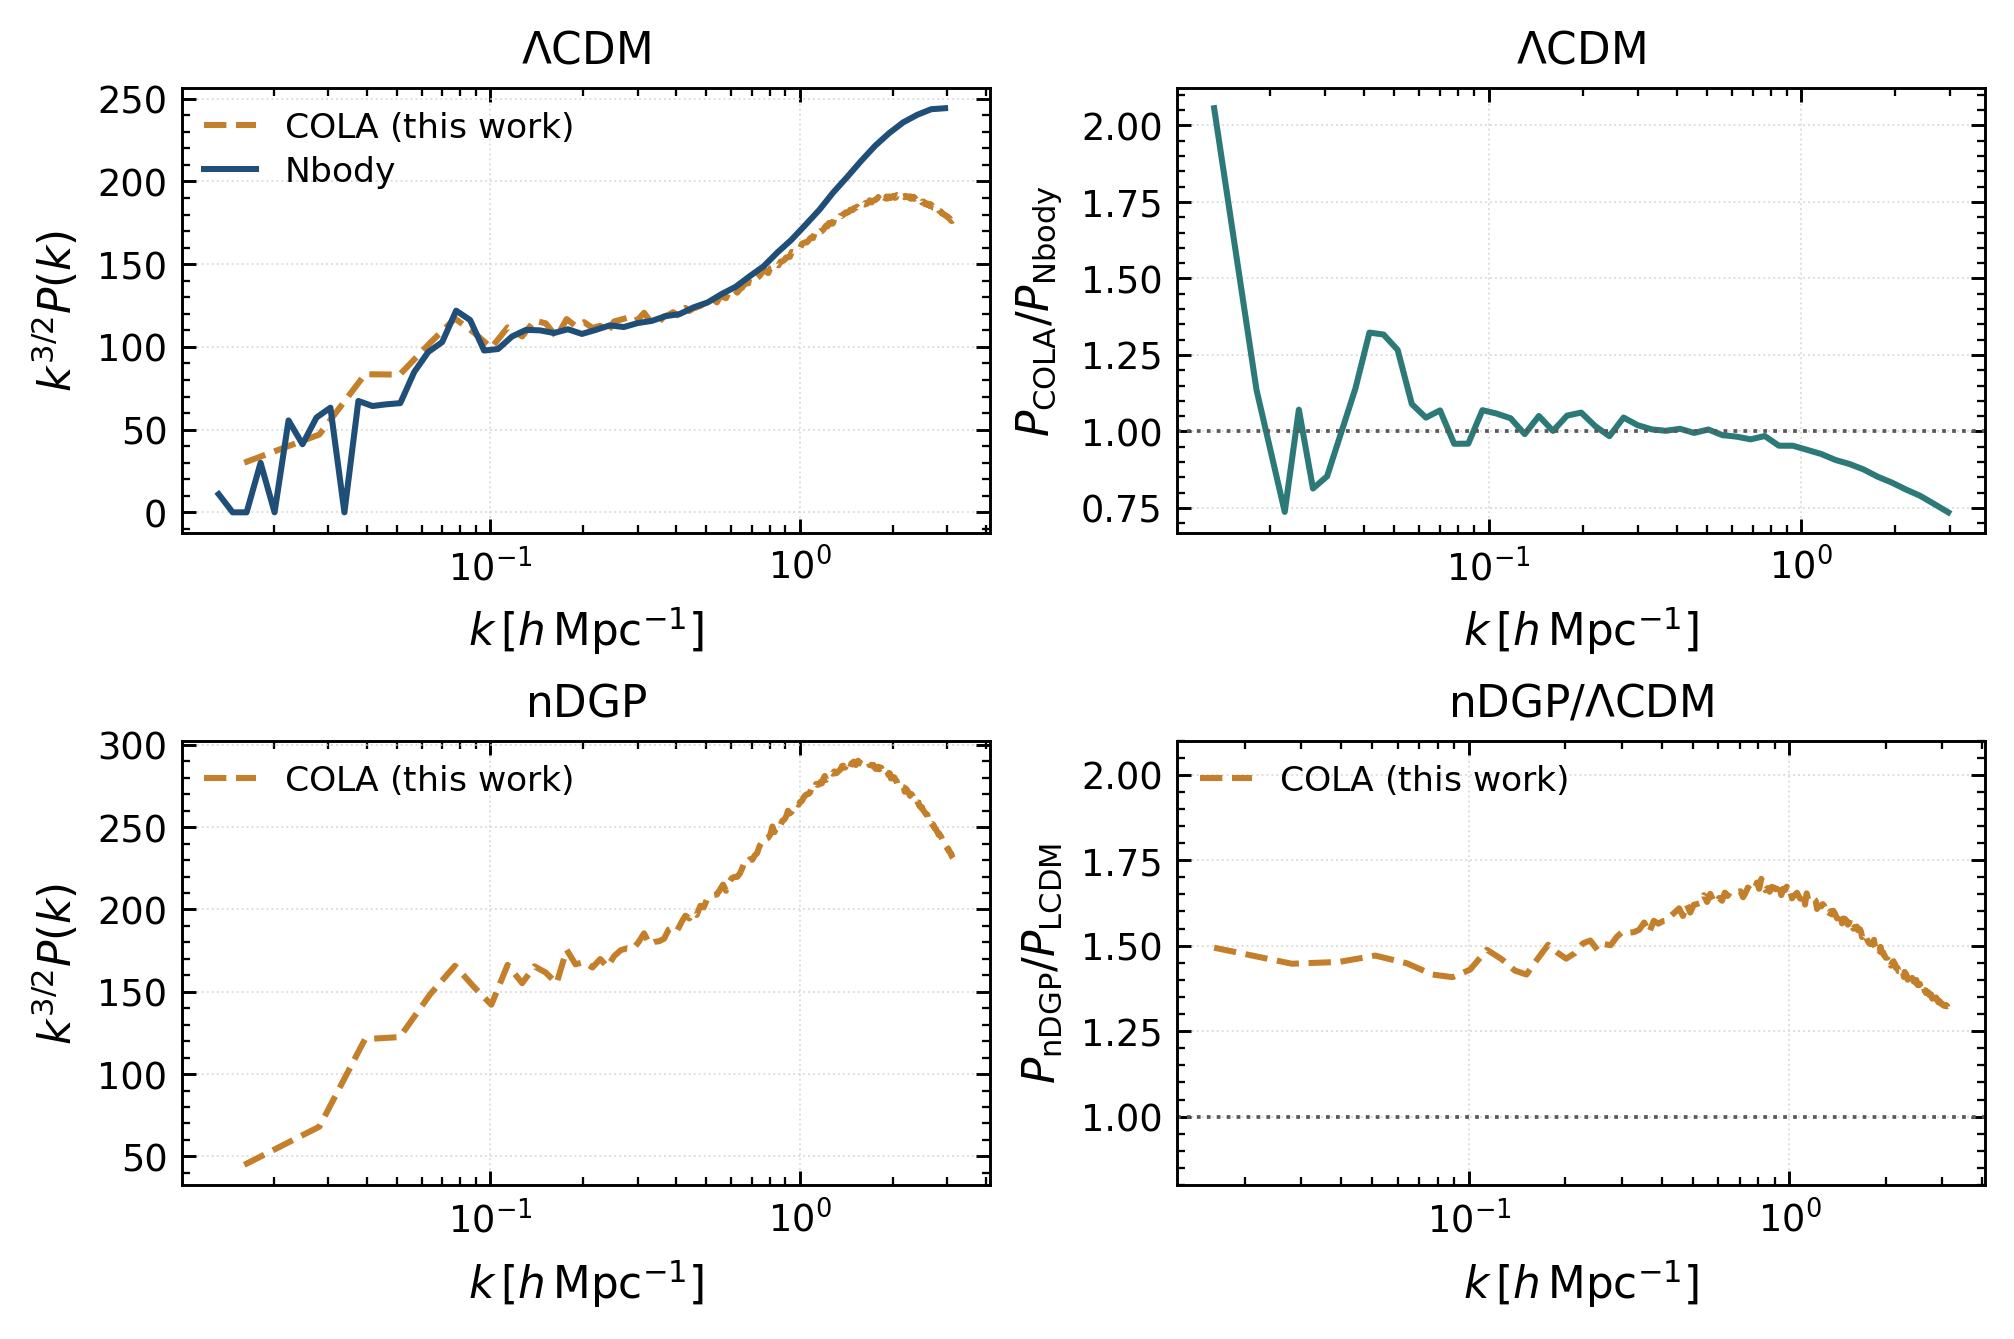

In [38]:
# Four-panel comparison at z=0.500: LCDM (top row) vs nDGP (bottom row)
k_LCDM_Abacus_plot = np.asarray(k_LCDM_Abacus)
Pk_LCDM_Abacus_plot = np.asarray(Pk_LCDM_Abacus)
abacus_label = r'$\mathrm{Nbody}$'

k_LCDM_Me_plot = np.asarray(k_LCDM_Abacus_Me)
Pk_LCDM_Me_plot = np.asarray(Pk_LCDM_Abacus_Me)
k_nDGP_Me_plot = np.asarray(k_nDGP_Abacus_Me)
Pk_nDGP_Me_plot = np.asarray(Pk_nDGP_Abacus_Me)

# Cap every curve (including the Abacus comparison itself) at the same max k used in
# power_spectrum2.ipynb's comparison plots -- the Bart box's k range.
k_LCDM_Bart_ref, _ = load_power_spectrum('/home/biel/Hi-COLA/Comparison/Box1/Bart_LCDM_snap_0.txt')
k_max_ref = np.asarray(k_LCDM_Bart_ref).max()

mask_LCDM_Abacus = k_LCDM_Abacus_plot <= k_max_ref
k_LCDM_Abacus_plot = k_LCDM_Abacus_plot[mask_LCDM_Abacus]
Pk_LCDM_Abacus_plot = Pk_LCDM_Abacus_plot[mask_LCDM_Abacus]

# Cut our LCDM power spectrum to the comparison's k range. There is no nDGP N-body
# comparison yet, so the nDGP curve is cut to the same k range as the LCDM comparison instead.
mask_LCDM_Me = (k_LCDM_Me_plot >= k_LCDM_Abacus_plot.min()) & (k_LCDM_Me_plot <= k_max_ref)
k_LCDM_Me_plot = k_LCDM_Me_plot[mask_LCDM_Me]
Pk_LCDM_Me_plot = Pk_LCDM_Me_plot[mask_LCDM_Me]

mask_nDGP_Me = (k_nDGP_Me_plot >= k_LCDM_Abacus_plot.min()) & (k_nDGP_Me_plot <= k_max_ref)
k_nDGP_Me_plot = k_nDGP_Me_plot[mask_nDGP_Me]
Pk_nDGP_Me_plot = Pk_nDGP_Me_plot[mask_nDGP_Me]

Pk_LCDM_Me_on_Abacus = np.interp(k_LCDM_Abacus_plot, k_LCDM_Me_plot, Pk_LCDM_Me_plot)
# A handful of the largest-scale Abacus bins have only a few Fourier modes, so shot-noise
# subtraction can push them to ~0 or slightly negative -- exclude those from the ratio.
mask_lcdm_ratio_valid = Pk_LCDM_Abacus_plot > 0
Pk_LCDM_COLA_over_Abacus = Pk_LCDM_Me_on_Abacus / Pk_LCDM_Abacus_plot

fig_size = (6.6, 4.35)
label_size = 10.5
tick_size = 8.8
legend_size = 8.3
line_width = 1.45
cola_color = '#c47f2b'
abacus_color = '#1f4e79'
ratio_color = '#2b7a78'
ref_color = '0.35'

fig, axes = plt.subplots(2, 2, figsize=fig_size, dpi=300, constrained_layout=True)
ax_tl, ax_tr = axes[0]
ax_bl, ax_br = axes[1]

# Top row: LCDM
ax_tl.semilogx(k_LCDM_Me_plot, k_LCDM_Me_plot**(3/2) * Pk_LCDM_Me_plot, lw=line_width, color=cola_color, ls='--', label=r'$\mathrm{COLA\ (this\ work)}$')
ax_tl.semilogx(k_LCDM_Abacus_plot, k_LCDM_Abacus_plot**(3/2) * Pk_LCDM_Abacus_plot, lw=line_width, color=abacus_color, label=abacus_label)
ax_tl.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=label_size)
ax_tl.set_ylabel(r'$k^{3/2} P(k)$', fontsize=label_size)
ax_tl.set_title(r'$\Lambda\mathrm{CDM}$', fontsize=label_size)
ax_tl.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25)

ax_tr.semilogx(k_LCDM_Abacus_plot[mask_lcdm_ratio_valid], Pk_LCDM_COLA_over_Abacus[mask_lcdm_ratio_valid], lw=line_width, color=ratio_color)
ax_tr.axhline(1.0, color=ref_color, lw=0.9, ls=':')
ax_tr.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=label_size)
ax_tr.set_ylabel(r'$P_{\mathrm{COLA}} / P_{\mathrm{Nbody}}$', fontsize=label_size)
ax_tr.set_title(r'$\Lambda\mathrm{CDM}$', fontsize=label_size)

# Bottom row: nDGP -- no N-body nDGP comparison yet, so only our simulation is shown
ax_bl.semilogx(k_nDGP_Me_plot, k_nDGP_Me_plot**(3/2) * Pk_nDGP_Me_plot, lw=line_width, color=cola_color, ls='--', label=r'$\mathrm{COLA\ (this\ work)}$')
ax_bl.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=label_size)
ax_bl.set_ylabel(r'$k^{3/2} P(k)$', fontsize=label_size)
ax_bl.set_title(r'$\mathrm{nDGP}$', fontsize=label_size)
ax_bl.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25)
ax_bl.set_xlim(ax_tl.get_xlim())
#ax_bl.set_ylim(ax_tl.get_ylim())

# No N-body nDGP comparison available yet, so this panel shows our own nDGP/LCDM
# ratio instead (previously a separate standalone figure).
Pk_nDGP_Me_on_LCDM = np.interp(k_LCDM_Me_plot, k_nDGP_Me_plot, Pk_nDGP_Me_plot)
ax_br.semilogx(k_LCDM_Me_plot, Pk_nDGP_Me_on_LCDM / Pk_LCDM_Me_plot, lw=line_width, color=cola_color, ls='--', label=r'$\mathrm{COLA\ (this\ work)}$')
ax_br.axhline(1.0, color=ref_color, lw=0.9, ls=':')
ax_br.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=label_size)
ax_br.set_ylabel(r'$P_{\mathrm{nDGP}} / P_{\mathrm{LCDM}}$', fontsize=label_size)
ax_br.set_ylim(0.8,2.1)
ax_br.set_title(r'$\mathrm{nDGP}/\Lambda\mathrm{CDM}$', fontsize=label_size)
ax_br.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25, loc='upper left')

for ax in (ax_tl, ax_tr, ax_bl, ax_br):
    ax.minorticks_on()
    ax.grid(True, which='major', ls=':', color='0.82', alpha=0.75, lw=0.45)
    ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, labelsize=tick_size, length=3.4, width=0.7)
    ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, labelsize=tick_size - 0.8, length=2.0, width=0.55)
    for spine in ax.spines.values():
        spine.set_linewidth(0.7)

plt.show()

# Load halo catalogs


In [34]:
def load_hmf_table(file):
    table = np.loadtxt(file, comments='#')
    return table[:, 0], table[:, 1]

# Our own COLA HMFs (no N-body HMF comparison available yet -- Abacus1's halo catalog
# is only in raw CompaSO/ASDF format, not processed into this n(>M) format).
LCDM_hmf_file = f'/scratch/biel/LCDM_Abacus/snapshot_LCDM_Abacus_z{abacus_redshift_label}/halo_catalog/halos200c_hmf.txt'
nDGP_hmf_file = f'/scratch/biel/nDGP_Abacus/snapshot_nDGP_Abacus_z{abacus_redshift_label}/halo_catalog/halos200c_hmf.txt'

M_LCDM_Me, hmf_LCDM_Me = load_hmf_table(LCDM_hmf_file)
M_nDGP_Me, hmf_nDGP_Me = load_hmf_table(nDGP_hmf_file)

# Plot 6


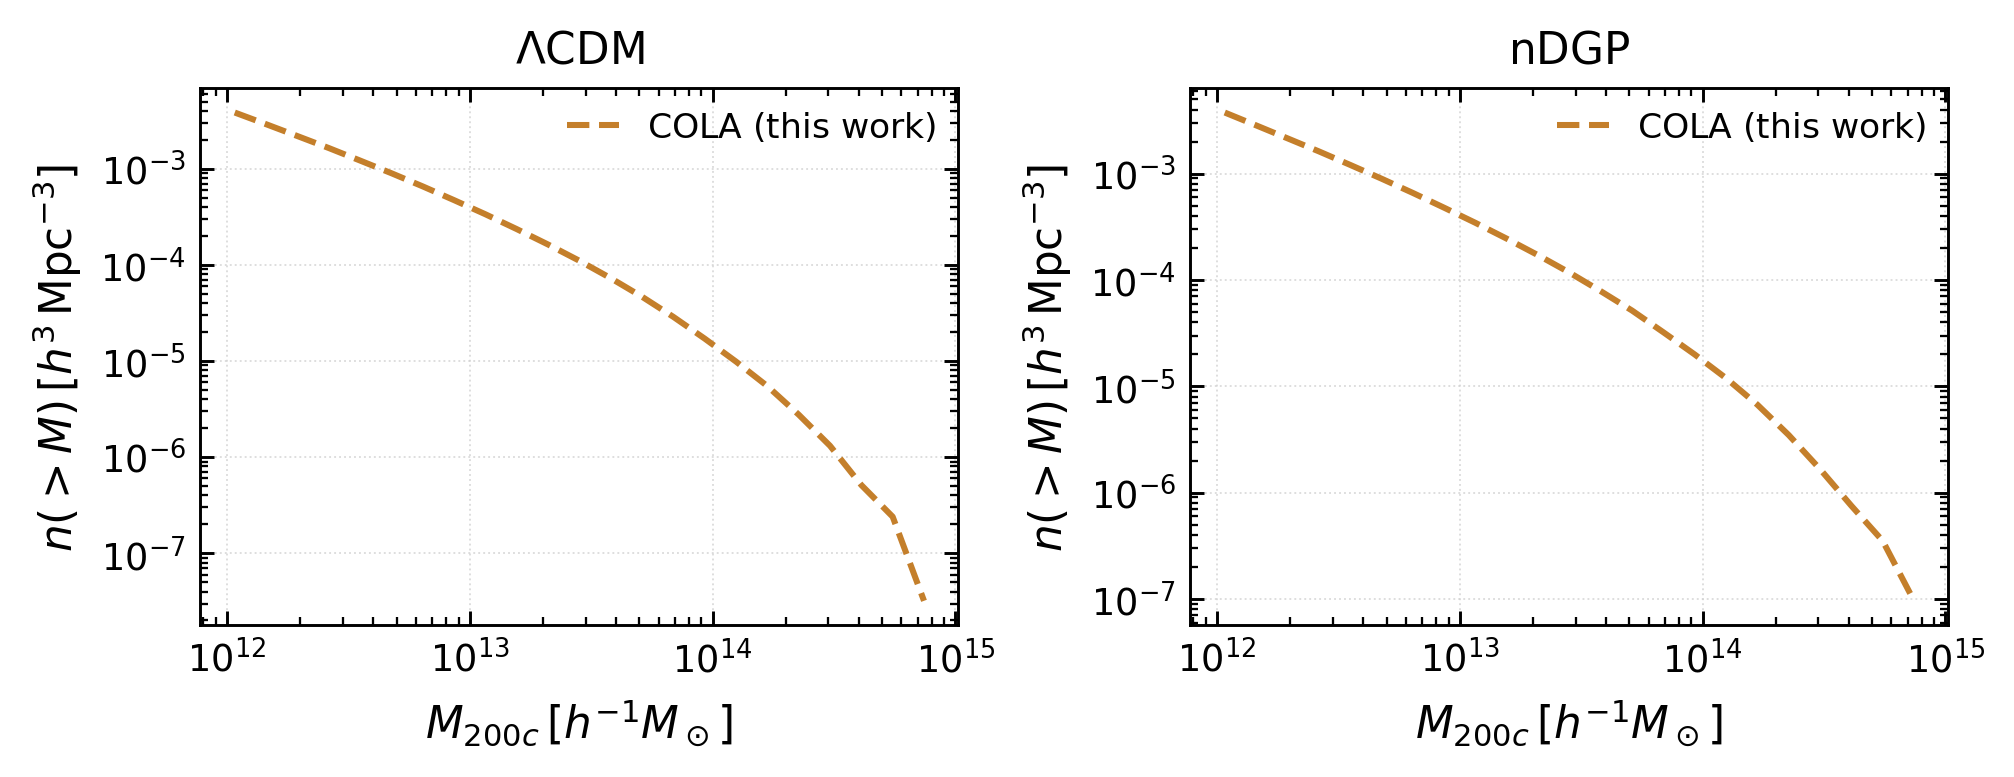

In [35]:
# Two-panel HMF comparison at z=0.500 (COLA only -- no N-body HMF comparison yet)
M_LCDM_Me_plot = np.asarray(M_LCDM_Me)
hmf_LCDM_Me_plot = np.asarray(hmf_LCDM_Me)
M_nDGP_Me_plot = np.asarray(M_nDGP_Me)
hmf_nDGP_Me_plot = np.asarray(hmf_nDGP_Me)

fig_size = (6.6, 4.35)
label_size = 10.5
tick_size = 8.8
legend_size = 8.3
line_width = 1.45
cola_color = '#c47f2b'

fig, axes = plt.subplots(2, 2, figsize=fig_size, dpi=300, constrained_layout=True)
ax_l, ax_r = axes[0]
ax_bl, ax_br = axes[1]

mask_lcdm = (hmf_LCDM_Me_plot > 0) & (M_LCDM_Me_plot >= 1e12)
ax_l.loglog(M_LCDM_Me_plot[mask_lcdm], hmf_LCDM_Me_plot[mask_lcdm], lw=line_width, color=cola_color, ls='--', label=r'$\mathrm{COLA\ (this\ work)}$')
ax_l.set_xlabel(r'$M_{200c}\,[h^{-1}M_\odot]$', fontsize=label_size)
ax_l.set_ylabel(r'$n(>M)\,[h^3\,\mathrm{Mpc}^{-3}]$', fontsize=label_size)
ax_l.set_title(r'$\Lambda\mathrm{CDM}$', fontsize=label_size)
ax_l.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25)

mask_ndgp = (hmf_nDGP_Me_plot > 0) & (M_nDGP_Me_plot >= 1e12)
ax_r.loglog(M_nDGP_Me_plot[mask_ndgp], hmf_nDGP_Me_plot[mask_ndgp], lw=line_width, color=cola_color, ls='--', label=r'$\mathrm{COLA\ (this\ work)}$')
ax_r.set_xlabel(r'$M_{200c}\,[h^{-1}M_\odot]$', fontsize=label_size)
ax_r.set_ylabel(r'$n(>M)\,[h^3\,\mathrm{Mpc}^{-3}]$', fontsize=label_size)
ax_r.set_title(r'$\mathrm{nDGP}$', fontsize=label_size)
ax_r.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25)

ax_bl.set_visible(False)
ax_br.set_visible(False)

for ax in (ax_l, ax_r):
    ax.minorticks_on()
    ax.grid(True, which='major', ls=':', color='0.82', alpha=0.75, lw=0.45)
    ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, labelsize=tick_size, length=3.4, width=0.7)
    ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, labelsize=tick_size - 0.8, length=2.0, width=0.55)
    for spine in ax.spines.values():
        spine.set_linewidth(0.7)

plt.show()

## Plot 6b: nDGP/LCDM HMF ratio (standalone, one-column figure)


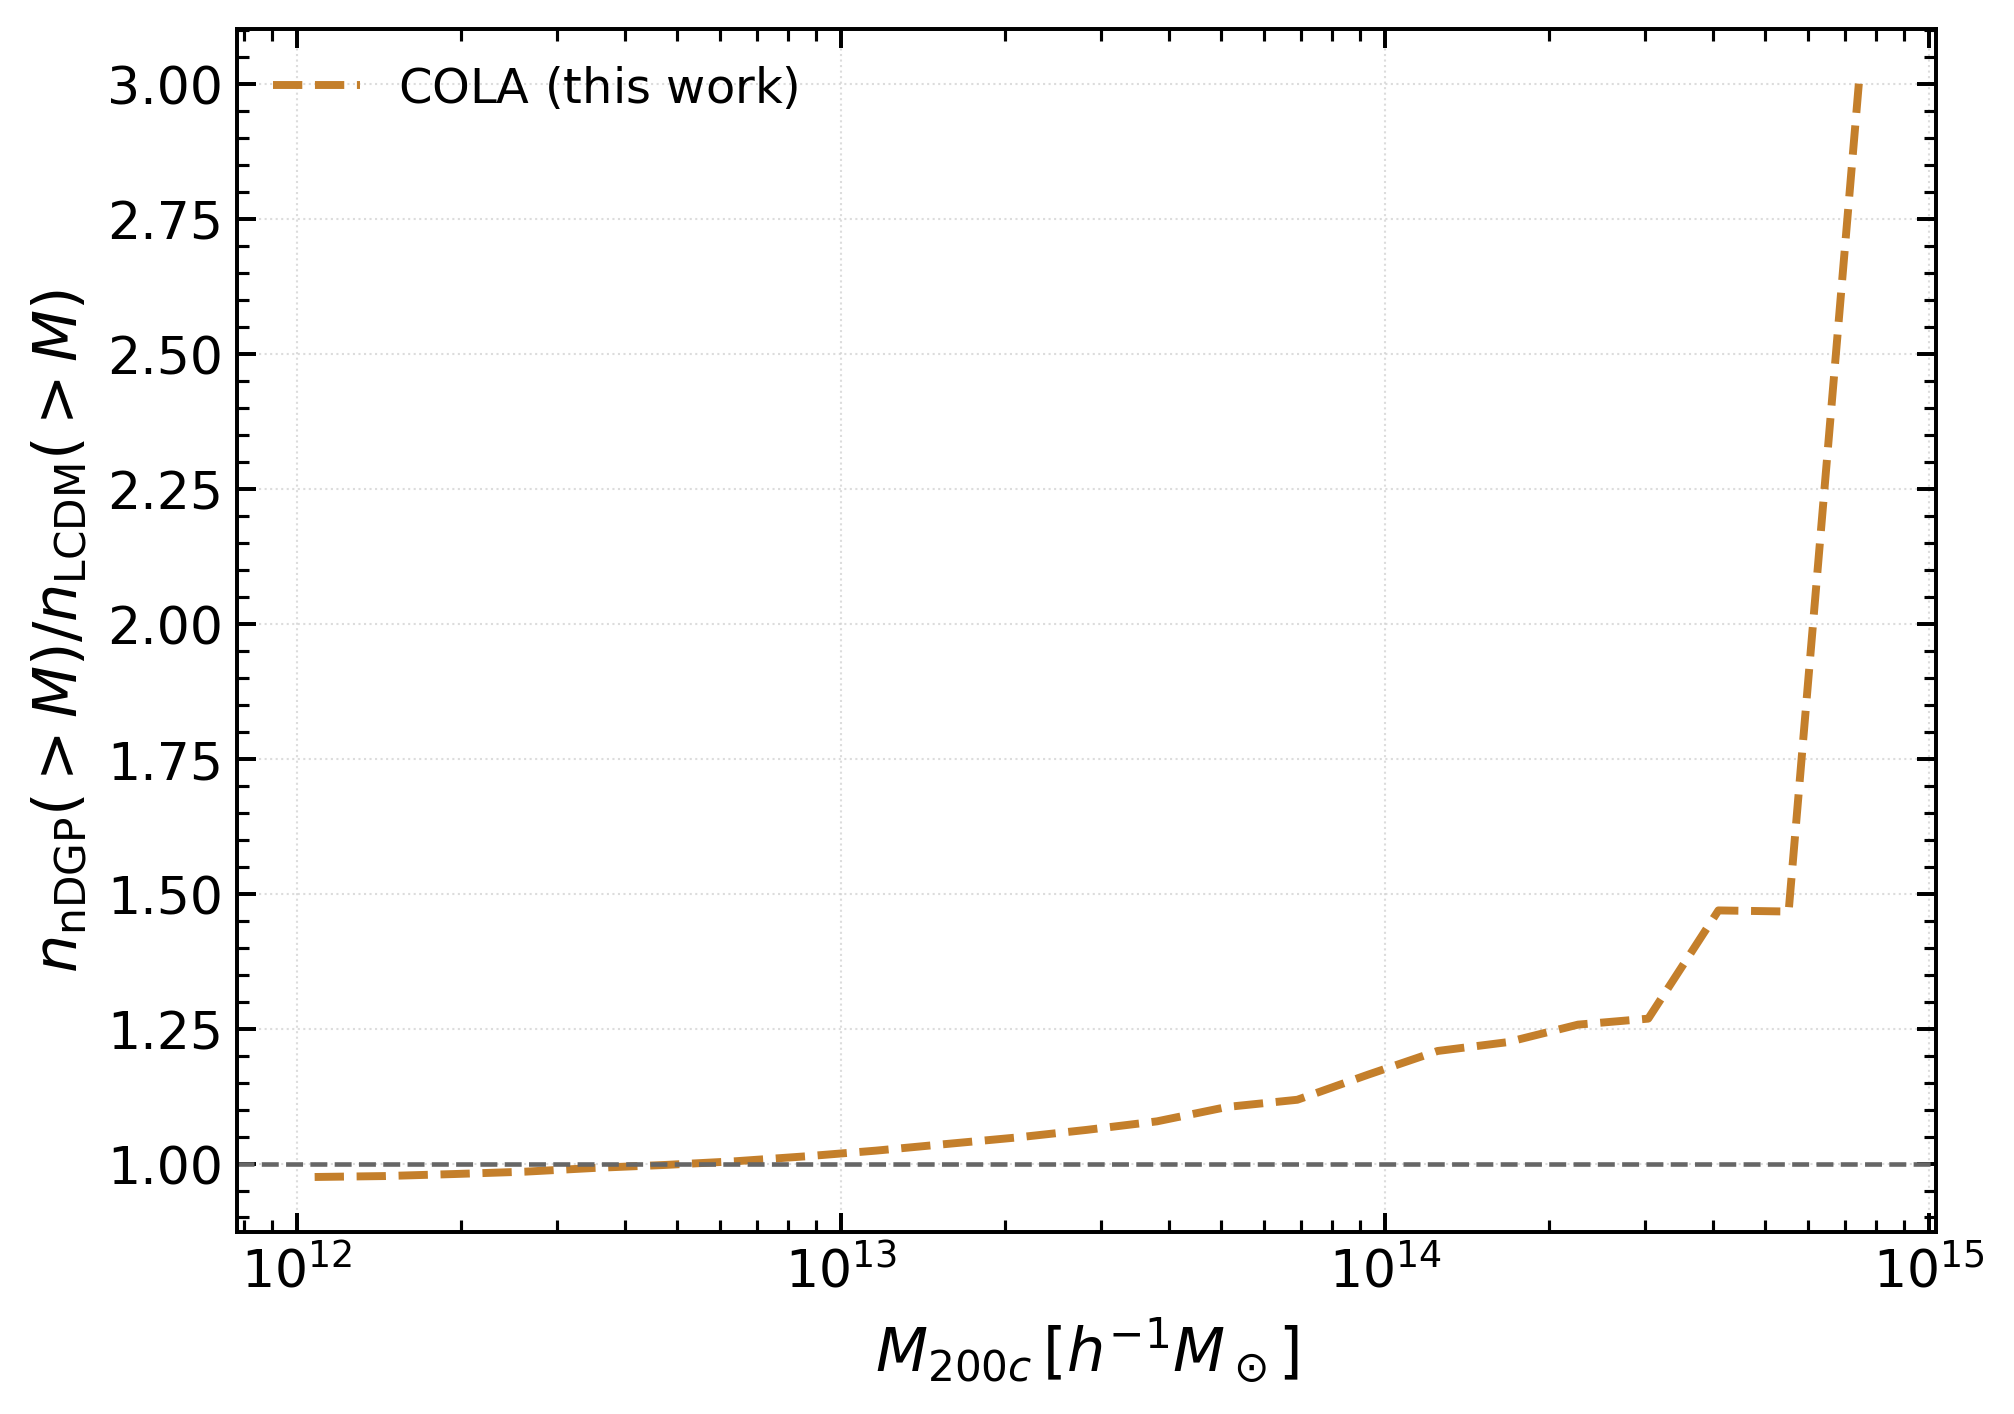

In [36]:
# nDGP / LCDM HMF ratio at z=0.500 (COLA only -- no N-body HMF comparison yet)
M_LCDM_Me_plot = np.asarray(M_LCDM_Me)
hmf_LCDM_Me_plot = np.asarray(hmf_LCDM_Me)
M_nDGP_Me_plot = np.asarray(M_nDGP_Me)
hmf_nDGP_Me_plot = np.asarray(hmf_nDGP_Me)

hmf_nDGP_Me_on_LCDM = np.interp(M_LCDM_Me_plot, M_nDGP_Me_plot, hmf_nDGP_Me_plot)
hmf_nDGP_over_LCDM_Me = np.divide(
    hmf_nDGP_Me_on_LCDM,
    hmf_LCDM_Me_plot,
    out=np.full_like(hmf_LCDM_Me_plot, np.nan, dtype=float),
    where=hmf_LCDM_Me_plot > 0,
)
mask_ratio = np.isfinite(hmf_nDGP_over_LCDM_Me) & (M_LCDM_Me_plot >= 1e12)

# This is a standalone, one-column figure (unlike the two-panel plot above), so it will be
# shrunk more to fit a document column -- sizes here are scaled up accordingly to stay readable.
fig_size = (6.6, 4.6)
label_size = 14.5
tick_size = 12.5
legend_size = 11.5
line_width = 1.9
cola_color = '#c47f2b'

fig, ax = plt.subplots(figsize=fig_size, dpi=300, constrained_layout=True)

ax.semilogx(M_LCDM_Me_plot[mask_ratio], hmf_nDGP_over_LCDM_Me[mask_ratio], lw=line_width, color=cola_color, ls='--', label=r'$\mathrm{COLA\ (this\ work)}$')
ax.set_xlabel(r'$M_{200c}\,[h^{-1}M_\odot]$', fontsize=label_size)
ax.set_ylabel(r'$n_{\mathrm{nDGP}}(>M) / n_{\mathrm{LCDM}}(>M)$', fontsize=label_size)
ax.legend(fontsize=legend_size, frameon=False, handlelength=1.8, borderaxespad=0.35, labelspacing=0.35)
ax.axhline(1.0, color='0.4', lw=1.1, ls='--')

ax.minorticks_on()
ax.grid(True, which='major', ls=':', color='0.82', alpha=0.75, lw=0.5)
ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, labelsize=tick_size, length=4.6, width=0.95)
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, labelsize=tick_size - 1.2, length=2.8, width=0.75)
for spine in ax.spines.values():
    spine.set_linewidth(0.95)

plt.show()